# Project 06 · Content-Based News Recommendation with Transformers

**Track:** Transformers / Recommendation  
**Research / product question:** Can article content support new-article recommendations without session-sequence modeling?

**Learning outcome:** TF-IDF similarity, learned transformer-encoder embeddings, hold-out articles, Recall@K and cold start.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

Represent each news article using text only; do **not** use a session Transformer. The small encoder learns from training-article topic labels, then a content similarity search recommends from the training catalog.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate topic-structured news articles

A small MIND-style news catalog contains paraphrases across six topics. We **do not** use MIND user histories or pretend the simulated titles are real news. Relevance is defined by known topic labels.

In [2]:
# The simulated topic vocabulary is simple; perfect metrics are not production evidence.
import torch,re
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
torch.manual_seed(42);torch.set_num_threads(2)
topics={
 'technology':['chip manufacturing','AI models','cloud software','robotics','data center'],
 'finance':['stock market','bond yields','central bank','corporate earnings','bank lending'],
 'sports':['football match','basketball team','tennis tournament','championship game','athlete training'],
 'science':['space mission','medical research','physics experiment','ocean discovery','climate science'],
 'travel':['airline routes','mountain hiking','hotel stays','city tourism','rail journeys'],
 'culture':['film festival','new novel','modern art','theater performance','music exhibition']}
phrases=['a detailed overview','new developments','explained for readers','weekly analysis','research outlook']
news=[]
for cat,terms in topics.items():
 for i in range(80):
    term=rng.choice(terms);phrase=rng.choice(phrases)
    news.append((cat,f'{term.title()}: {phrase} {i%9}',f'Report about {term} with {rng.choice(["expert insights","recent events","industry trends"])} and {phrase}.'))
news=pd.DataFrame(news,columns=['topic','title','summary']);news['text']=news.title+' '+news.summary
print(news.sample(4,random_state=42).to_string(index=False))

     topic                                     title                                                                       summary                                                                                                                    text
technology        Data Center: a detailed overview 1          Report about data center with recent events and a detailed overview.                 Data Center: a detailed overview 1 Report about data center with recent events and a detailed overview.
   culture Music Exhibition: explained for readers 5 Report about music exhibition with industry trends and explained for readers. Music Exhibition: explained for readers 5 Report about music exhibition with industry trends and explained for readers.
    travel     City Tourism: explained for readers 2       Report about city tourism with recent events and explained for readers.           City Tourism: explained for readers 2 Report about city tourism with recent events and explained for reade

## 2. Split articles and build a lexical baseline

With content-based recommenders, candidates can be unseen articles. Splitting items (not just interactions) tests whether the model handles cold-start news; TF-IDF fitting uses training text only.

In [3]:
# Split news articles, not individual tokens, to evaluate unseen documents.
tr,te=train_test_split(np.arange(len(news)),test_size=.25,stratify=news.topic,random_state=42)
tr,va=train_test_split(tr,test_size=.20,stratify=news.topic.iloc[tr],random_state=42)
# Retrieval catalog = training articles, and validation/test articles are only seeds.
vec=TfidfVectorizer(ngram_range=(1,2),min_df=1).fit(news.text.iloc[tr])
training_vectors=vec.transform(news.text.iloc[tr])
def content_recall_at_5(sim,seedids,corpusids):
 wanted=news.topic.iloc[seedids].to_numpy();candidate_topics=news.topic.iloc[corpusids].to_numpy()
 top=np.argsort(-sim,axis=1)[:,:5]
 return np.mean([t in candidate_topics[x] for t,x in zip(wanted,top)])
lex_val=cosine_similarity(vec.transform(news.text.iloc[va]),training_vectors)
print('TF-IDF validation Recall@5:',round(content_recall_at_5(lex_val,va,tr),3))

TF-IDF validation Recall@5: 1.0


## 3. Train a transformer text encoder from random initialization

The Transformer Encoder uses **self-attention** to create article representations. Topic classification is the supervised proxy task; at recommendation time we compare document embeddings via cosine similarity. This is an educational supervised representation baseline.

Validation Recall@5 by embedding dimension: {24: np.float64(1.0), 48: np.float64(1.0)}


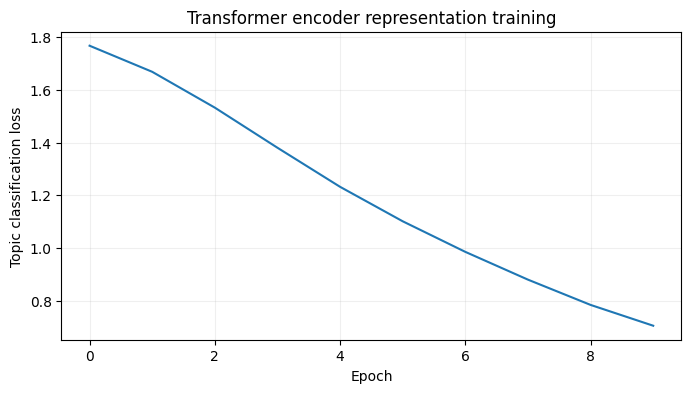

In [4]:
# Transformer encoder represents documents; use cosine similarity for neighbors.
from collections import Counter
def tokenize(s):return re.findall(r'[a-z]+',s.lower())
count=Counter(w for s in news.text.iloc[tr] for w in tokenize(s));vocab={'<PAD>':0,'<UNK>':1};vocab.update({w:i+2 for i,(w,_) in enumerate(count.most_common())});maxlen=19
ids=np.zeros((len(news),maxlen),dtype='int64')
for i,s in enumerate(news.text):
 tok=[vocab.get(w,1) for w in tokenize(s)[:maxlen]];ids[i,:len(tok)]=tok
X=torch.tensor(ids);topic_id={c:i for i,c in enumerate(topics)};labels=torch.tensor(news.topic.map(topic_id).to_numpy())
class NewsEncoder(nn.Module):
 def __init__(self,dim=32,drop=.1):
    super().__init__();self.emb=nn.Embedding(len(vocab),dim,padding_idx=0);self.pos=nn.Embedding(maxlen,dim)
    layer=nn.TransformerEncoderLayer(dim,4,dim_feedforward=2*dim,dropout=drop,batch_first=True)
    self.transformer=nn.TransformerEncoder(layer,1,enable_nested_tensor=False)
    self.head=nn.Linear(dim,len(topics))
 def encode(self,x):
    e=self.emb(x)+self.pos(torch.arange(x.shape[1])[None,:]);mask=x==0
    h=self.transformer(e,src_key_padding_mask=mask);pooled=(h*(~mask).unsqueeze(-1)).sum(1)/(~mask).sum(1,keepdim=True).clamp(min=1)
    return nn.functional.normalize(pooled,dim=-1)
 def forward(self,x):return self.head(self.encode(x))
def fit_news(dim=32,drop=.1):
 torch.manual_seed(42);m=NewsEncoder(dim,drop);opt=torch.optim.AdamW(m.parameters(),lr=.004);hist=[]
 for ep in range(10):
    m.train();losses=[]
    for ix in np.array_split(np.random.default_rng(ep).permutation(tr),8):
      loss=nn.functional.cross_entropy(m(X[ix]),labels[ix]);opt.zero_grad();loss.backward();opt.step();losses.append(loss.item())
    hist.append(float(np.mean(losses)))
 return m,hist
def similarity(m,seeds,catalog):
 m.eval()
 with torch.no_grad():return (m.encode(X[seeds])@m.encode(X[catalog]).T).numpy()
config={}
for dim in [24,48]:
 m,curve=fit_news(dim);score=content_recall_at_5(similarity(m,va,tr),va,tr);config[dim]=(m,curve,score)
print('Validation Recall@5 by embedding dimension:',{d:round(x[2],3) for d,x in config.items()})
bestdim=max(config,key=lambda d:config[d][2]);best,loss_curve,_=config[bestdim]
plt.plot(loss_curve);plt.xlabel('Epoch');plt.ylabel('Topic classification loss');plt.title('Transformer encoder representation training');plt.show()

## 4. Final cold-start recommendation evaluation

We evaluate **unseen seed articles** against the known catalog. Recall@5 here means at least one recommended article is in the same synthetic topic; this proxy is not a real user-satisfaction metric.

Unseen-news Recall@5: {'TF-IDF': np.float64(1.0), 'Transformer encoder': np.float64(1.0)}


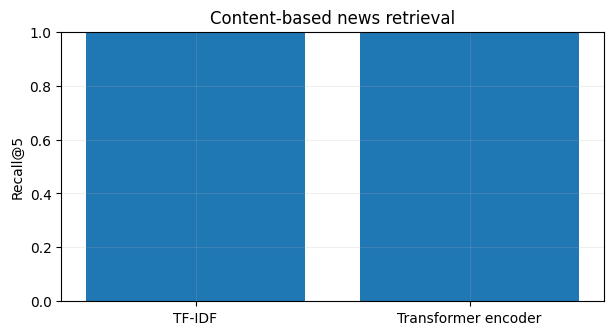

Seed article: Stock Market: explained for readers 0
Recommended:
                                 title   topic
Stock Market: explained for readers 2 finance
Stock Market: explained for readers 6 finance
Stock Market: explained for readers 8 finance
      Stock Market: weekly analysis 7 finance
      Stock Market: weekly analysis 5 finance


In [5]:
# Inspect held-out recommendations and report retrieval quality.
lex_test=cosine_similarity(vec.transform(news.text.iloc[te]),training_vectors);sim_test=similarity(best,te,tr)
metrics={'TF-IDF':content_recall_at_5(lex_test,te,tr),'Transformer encoder':content_recall_at_5(sim_test,te,tr)}
print('Unseen-news Recall@5:',metrics)
fig,ax=plt.subplots(figsize=(7,3.5));ax.bar(list(metrics),list(metrics.values()));ax.set(ylim=(0,1),ylabel='Recall@5',title='Content-based news retrieval');plt.show()
example=0;index=te[example];rank=np.argsort(-sim_test[example])[:5]
print('Seed article:',news.title.iloc[index]);print('Recommended:\n',news.iloc[tr[rank]][['title','topic']].to_string(index=False))

## What the results mean / interview discussion

Content-only recommendation avoids sequence models and can serve new articles. The simulated topics are intentionally separable, so TF-IDF may match or outperform a small scratch-trained Transformer. The next credible validation is Microsoft MIND-small with impression-level relevance and proper temporal splits; use those data rather than asserting production quality from toy recall.

**Try explaining these without looking at the code:**

1. Why is article cold start easier for content-based than collaborative filtering?
2. How would you score users with multiple liked articles?
3. How can relevance, diversity and popularity bias conflict?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Important:** Topic-based Recall@5 is a deliberately *coarse synthetic proxy*, not user satisfaction. The generator uses separable topic vocabularies; scores can saturate at 1.0. **Next:** test on MIND-small with real impressions and compare click-aware NDCG, diversity and coverage.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.

{'Random': np.float64(0.55), 'TF-IDF': np.float64(1.0), 'Transformer': np.float64(1.0)}


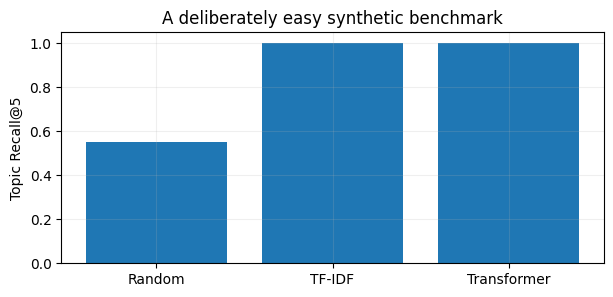

In [6]:
# A saturated toy benchmark should be reported honestly, including a random baseline.
random_sim = np.random.default_rng(8).random(lex_test.shape)
random_rec = content_recall_at_5(random_sim, te, tr)
comparison = {"Random": random_rec, "TF-IDF": metrics["TF-IDF"],
              "Transformer": metrics["Transformer encoder"]}
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(list(comparison), list(comparison.values()))
ax.set(ylim=(0, 1.05), ylabel="Topic Recall@5", title="A deliberately easy synthetic benchmark")
print({k: round(v, 3) for k, v in comparison.items()})
plt.show()

**Why the scores saturate:** Category-specific vocabulary makes topic retrieval nearly trivial, even for a lexical baseline. That is useful for verifying code, but a next project iteration must use overlapping vocabularies, implicit feedback and real news impressions (MIND-small).